In [72]:
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn streamlit joblib

Note: you may need to restart the kernel to use updated packages.


In [117]:
# Import libraries required for data preparation and analysis

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Retrieve the Online Shoppers Purchasing Intention dataset
shopper_dataset = fetch_ucirepo(id=468)

# Extract visitor-related attributes
visitor_data = shopper_dataset.data.features

# Extract the purchase outcome
purchase_labels = shopper_dataset.data.targets

# Combine input attributes and target into a single DataFrame
shopper_df = pd.concat(
    [visitor_data, purchase_labels],
    axis=1
)

# Export the dataset for future experiments and deployment
shopper_df.to_csv(
    "online_shoppers_intention.csv",
    index=False
)

# Display basic dataset information
print("Online shopping dataset loaded successfully!")
print("Dataset dimensions:", shopper_df.shape)
print("Total observations:", shopper_df.shape[0])
print("Total columns:", shopper_df.shape[1])

Online shopping dataset loaded successfully!
Dataset dimensions: (12330, 18)
Total observations: 12330
Total columns: 18


In [119]:
# Inspect a sample of shopping session records

shopper_df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [121]:
# Examine column names, data types and non-null record counts

print("Dataset structure:")
shopper_df.info()

Dataset structure:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  Tra

In [123]:
# Generate descriptive statistics for numerical and categorical attributes

dataset_summary = shopper_df.describe(include="all").transpose()

display(dataset_summary.round(3))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [125]:
# Identify missing observations in each dataset column

missing_summary = shopper_df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing_summary,
    "Missing_Percentage": (
        missing_summary / len(shopper_df) * 100
    ).round(2)
})

display(missing_report)

,Missing_Count,Missing_Percentage
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


In [127]:
# Summarize dataset dimensions and target distribution

total_records = shopper_df.shape[0]
total_columns = shopper_df.shape[1]
total_features = total_columns - 1
missing_entries = shopper_df.isnull().sum().sum()

print("=" * 45)
print("       ONLINE SHOPPING DATASET OVERVIEW")
print("=" * 45)

print(f"Total observations       : {total_records}")
print(f"Total columns            : {total_columns}")
print(f"Number of input features : {total_features}")
print(f"Missing values           : {missing_entries}")

# Analyze the distribution of purchase outcomes

print("\nPurchase Outcome Distribution:")

purchase_counts = shopper_df["Revenue"].value_counts()

print(purchase_counts.rename({
    False: "No Purchase",
    True: "Purchase"
}))

print("\nPurchase Outcome Percentage:")

purchase_percentages = (
    shopper_df["Revenue"]
    .value_counts(normalize=True)
    .mul(100)
)

print(purchase_percentages.rename({
    False: "No Purchase",
    True: "Purchase"
}).round(2))

       ONLINE SHOPPING DATASET OVERVIEW
Total observations       : 12330
Total columns            : 18
Number of input features : 17
Missing values           : 0

Purchase Outcome Distribution:
Revenue
No Purchase    10422
Purchase        1908
Name: count, dtype: int64

Purchase Outcome Percentage:
Revenue
No Purchase    84.53
Purchase       15.47
Name: proportion, dtype: float64


In [129]:
# Categorize input attributes based on their data types and meaning

numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

# Display feature categorization details

print("NUMERICAL ATTRIBUTES:")
print(numerical_features)

print("\nCATEGORICAL ATTRIBUTES:")
print(categorical_features)

print("\nFeature Summary:")
print("Numerical attributes  :", len(numerical_features))
print("Categorical attributes:", len(categorical_features))
print("Total input features  :", len(numerical_features) + len(categorical_features))

# Validate feature definitions
assert len(numerical_features) == 10
assert len(categorical_features) == 7
assert set(numerical_features + categorical_features) == set(
    shopper_df.drop(columns=["Revenue"]).columns
)

print("\nFeature validation completed successfully!")

NUMERICAL ATTRIBUTES:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

CATEGORICAL ATTRIBUTES:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Feature Summary:
Numerical attributes  : 10
Categorical attributes: 7
Total input features  : 17

Feature validation completed successfully!


In [131]:
# Separate predictor variables from the purchase outcome

input_features = shopper_df.drop(columns=["Revenue"])
target_labels = shopper_df["Revenue"]

# Verify the dimensions of both datasets

print("Input feature dimensions:", input_features.shape)
print("Target variable dimensions:", target_labels.shape)

print("\nTarget data type:", target_labels.dtype)
print("Unique target classes:", target_labels.unique())

Input feature dimensions: (12330, 17)
Target variable dimensions: (12330,)

Target data type: bool
Unique target classes: [False  True]


In [133]:
from sklearn.model_selection import train_test_split

# Reserve a portion of the dataset for unbiased model evaluation

(
    training_features,
    testing_features,
    training_labels,
    testing_labels
) = train_test_split(
    input_features,
    target_labels,
    test_size=0.20,
    random_state=42,
    stratify=target_labels
)

# Display the resulting dataset dimensions

print("Training feature dimensions:", training_features.shape)
print("Testing feature dimensions :", testing_features.shape)

print("\nTraining purchase distribution:")
print(training_labels.value_counts())

print("\nTesting purchase distribution:")
print(testing_labels.value_counts())

# Verify that the split contains the expected number of records

assert len(training_features) + len(testing_features) == len(shopper_df)

print("\nTraining and testing datasets prepared successfully!")

Training feature dimensions: (9864, 17)
Testing feature dimensions : (2466, 17)

Training purchase distribution:
Revenue
False    8338
True     1526
Name: count, dtype: int64

Testing purchase distribution:
Revenue
False    2084
True      382
Name: count, dtype: int64

Training and testing datasets prepared successfully!


In [135]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Configure transformations for numerical and categorical attributes

feature_processor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

print("Feature preprocessing pipeline initialized successfully!")
print("Numerical transformation: StandardScaler")
print("Categorical transformation: OneHotEncoder")

Feature preprocessing pipeline initialized successfully!
Numerical transformation: StandardScaler
Categorical transformation: OneHotEncoder


In [137]:
# Import classification algorithms and pipeline utilities

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

print("All five classification algorithms imported successfully!")

All five classification algorithms imported successfully!


In [157]:

# Configure the five classifiers for purchase prediction

from sklearn.calibration import CalibratedClassifierCV

classifier_pipelines = {

    "Logistic Regression": Pipeline([
        ("feature_processing", feature_processor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("feature_processing", feature_processor),
        ("classifier", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("feature_processing", feature_processor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("feature_processing", feature_processor),
        ("classifier", GaussianNB())
    ]),

    "Support Vector Machine": Pipeline([
        ("feature_processing", feature_processor),
        ("classifier", CalibratedClassifierCV(
            estimator=SVC(
                kernel="rbf",
                class_weight="balanced",
                random_state=42
            ),
            method="sigmoid",
            cv=3,
            ensemble=False
        ))
    ])
}

# Display the configured classification algorithms

print("CLASSIFICATION MODELS INITIALIZED")
print("-" * 45)

for classifier_name in classifier_pipelines:
    print(f"✓ {classifier_name}")

print("-" * 45)
print("Total classifiers configured:", len(classifier_pipelines))


CLASSIFICATION MODELS INITIALIZED
---------------------------------------------
✓ Logistic Regression
✓ Decision Tree
✓ K-Nearest Neighbors
✓ Gaussian Naive Bayes
✓ Support Vector Machine
---------------------------------------------
Total classifiers configured: 5


In [159]:
import time

# Store the execution duration of each classifier
training_duration = {}

print("=" * 50)
print("       CLASSIFIER TRAINING STARTED")
print("=" * 50)

# Train each model using the prepared training dataset
for classifier_name, classifier_pipeline in classifier_pipelines.items():

    print(f"\nTraining model: {classifier_name}")

    # Record the training start time
    start_time = time.perf_counter()

    # Fit preprocessing transformations and train the classifier
    classifier_pipeline.fit(
        training_features,
        training_labels
    )

    # Calculate total execution time
    elapsed_time = time.perf_counter() - start_time

    training_duration[classifier_name] = elapsed_time

    print(f"Training completed in {elapsed_time:.2f} seconds")

print("\n" + "=" * 50)
print("ALL FIVE CLASSIFIERS TRAINED SUCCESSFULLY!")
print("=" * 50)

       CLASSIFIER TRAINING STARTED

Training model: Logistic Regression
Training completed in 3.04 seconds

Training model: Decision Tree
Training completed in 0.20 seconds

Training model: K-Nearest Neighbors
Training completed in 0.04 seconds

Training model: Gaussian Naive Bayes
Training completed in 0.05 seconds

Training model: Support Vector Machine
Training completed in 17.62 seconds

ALL FIVE CLASSIFIERS TRAINED SUCCESSFULLY!


In [161]:
# Import performance evaluation metrics for binary classification

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

print("All six evaluation metrics imported successfully!")

# Store evaluation results for all trained classifiers

evaluation_records = []

print("=" * 55)
print("          CLASSIFIER PERFORMANCE EVALUATION")
print("=" * 55)

for classifier_name, classifier_pipeline in classifier_pipelines.items():

    print(f"\nEvaluating: {classifier_name}")

    # Generate predictions on unseen testing records
    predicted_labels = classifier_pipeline.predict(testing_features)

    # Obtain scores for ROC-AUC calculation
    if hasattr(classifier_pipeline, "predict_proba"):

        class_probabilities = classifier_pipeline.predict_proba(
            testing_features
        )

        positive_class_index = list(
            classifier_pipeline.classes_
        ).index(True)

        purchase_scores = class_probabilities[:, positive_class_index]

    else:
        # SVM uses decision scores instead of probabilities
        decision_scores = classifier_pipeline.decision_function(
            testing_features
        )

        # Ensure positive scores correspond to the Purchase class
        positive_class_index = list(
            classifier_pipeline.classes_
        ).index(True)

        purchase_scores = (
            decision_scores if positive_class_index == 1
            else -decision_scores
        )

    # Calculate the six required evaluation metrics
    model_metrics = {
        "Model": classifier_name,

        "Accuracy": accuracy_score(
            testing_labels, predicted_labels
        ),

        "AUC": roc_auc_score(
            testing_labels, purchase_scores
        ),

        "Precision": precision_score(
            testing_labels, predicted_labels,
            pos_label=True, zero_division=0
        ),

        "Recall": recall_score(
            testing_labels, predicted_labels,
            pos_label=True, zero_division=0
        ),

        "F1 Score": f1_score(
            testing_labels, predicted_labels,
            pos_label=True, zero_division=0
        ),

        "MCC": matthews_corrcoef(
            testing_labels, predicted_labels
        )
    }

    evaluation_records.append(model_metrics)

print("\n" + "=" * 55)
print("ALL FIVE CLASSIFIERS EVALUATED SUCCESSFULLY!")
print("=" * 55)

All six evaluation metrics imported successfully!
          CLASSIFIER PERFORMANCE EVALUATION

Evaluating: Logistic Regression

Evaluating: Decision Tree

Evaluating: K-Nearest Neighbors

Evaluating: Gaussian Naive Bayes

Evaluating: Support Vector Machine

ALL FIVE CLASSIFIERS EVALUATED SUCCESSFULLY!


In [165]:
# Prepare the consolidated performance summary

performance_summary = pd.DataFrame(evaluation_records)

# Display all five classifiers and their evaluation metrics
print("=" * 60)
print("CLASSIFICATION MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(performance_summary.round(4))

CLASSIFICATION MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8410,0.8932,0.4913,0.7435,0.5917,0.5145
1,Decision Tree,0.8487,0.7127,0.5117,0.5157,0.5137,0.4241
2,K-Nearest Neighbors,0.8767,0.7633,0.6822,0.3822,0.4899,0.4493
3,Gaussian Naive Bayes,0.2729,0.7334,0.1726,0.9738,0.2933,0.1289
4,Support Vector Machine,0.8820,0.8979,0.6631,0.4843,0.5598,0.5017


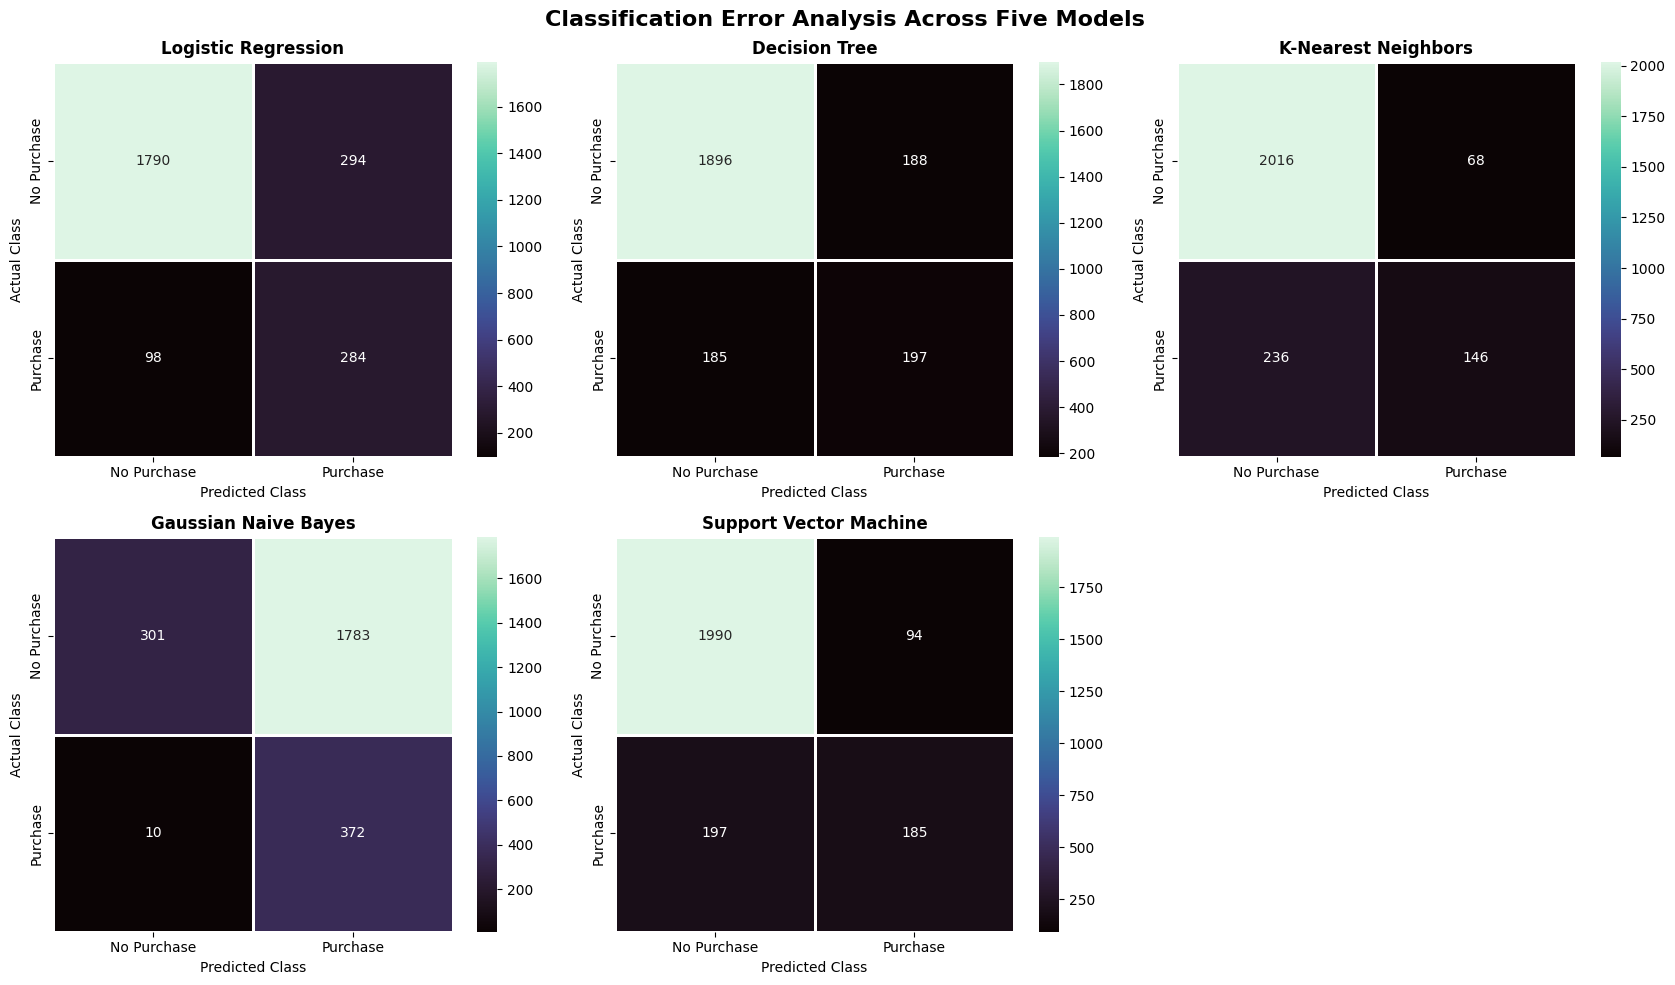

In [167]:
# Visual comparison of classification errors across all models

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Configure the visualization layout
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

plot_axes = axes.flatten()

# Generate confusion matrices for each classifier
for position, (classifier_name, classifier_pipeline) in enumerate(
    classifier_pipelines.items()
):

    # Predict outcomes using the testing dataset
    predicted_labels = classifier_pipeline.predict(testing_features)

    # Calculate confusion matrix
    matrix_values = confusion_matrix(
        testing_labels,
        predicted_labels,
        labels=[False, True]
    )

    # Draw heatmap
    sns.heatmap(
        matrix_values,
        annot=True,
        fmt="d",
        cmap="mako",
        linewidths=1,
        linecolor="white",
        xticklabels=["No Purchase", "Purchase"],
        yticklabels=["No Purchase", "Purchase"],
        cbar=True,
        ax=plot_axes[position]
    )

    plot_axes[position].set_title(
        classifier_name,
        fontsize=12,
        fontweight="bold"
    )

    plot_axes[position].set_xlabel("Predicted Class")
    plot_axes[position].set_ylabel("Actual Class")

# Remove unused subplot
fig.delaxes(plot_axes[5])

fig.suptitle(
    "Classification Error Analysis Across Five Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

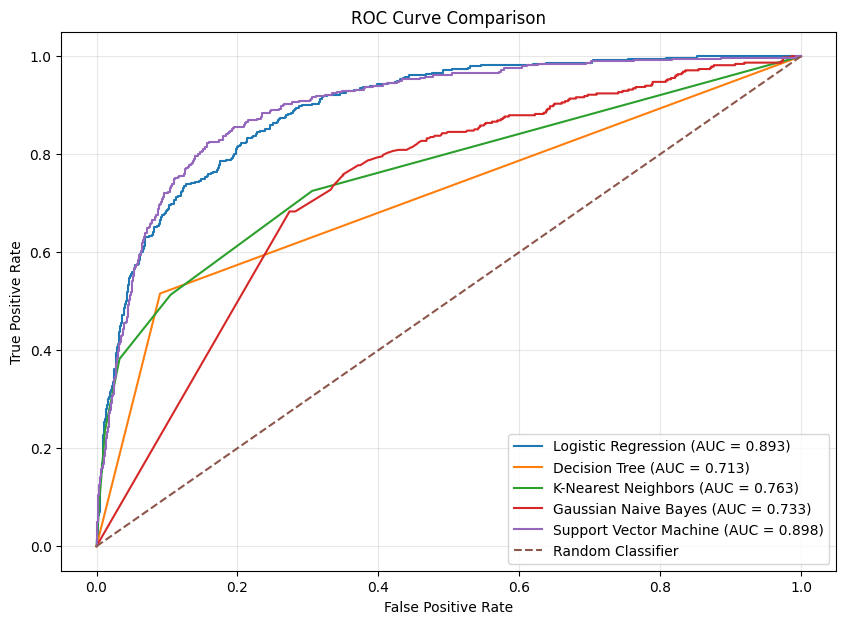

In [169]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for name, model in classifier_pipelines.items():

    # Get probability scores for Purchase class
    positive_index = list(model.classes_).index(True)

    y_prob = model.predict_proba(
        testing_features
    )[:, positive_index]

    # Calculate ROC values
    fpr, tpr, thresholds = roc_curve(
        testing_labels,
        y_prob,
        pos_label=True
    )

    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.3f})'
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [171]:
# Save trained classification pipelines and evaluation results

import os
import joblib

# Create a directory for storing trained classifiers
os.makedirs("trained_classifiers", exist_ok=True)

# Save all five trained classification pipelines
for classifier_name, classifier_pipeline in classifier_pipelines.items():

    # Generate a clean filename
    safe_filename = (
        classifier_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    model_path = os.path.join(
        "trained_classifiers",
        safe_filename + ".pkl"
    )

    joblib.dump(classifier_pipeline, model_path)

    print(f"Model saved successfully: {model_path}")

# Export model evaluation metrics
performance_summary.to_csv(
    "classifier_performance_summary.csv",
    index=False
)

print("\n" + "=" * 55)
print("ALL CLASSIFIERS AND EVALUATION RESULTS SAVED!")
print("=" * 55)

Model saved successfully: trained_classifiers/logistic_regression.pkl
Model saved successfully: trained_classifiers/decision_tree.pkl
Model saved successfully: trained_classifiers/k_nearest_neighbors.pkl
Model saved successfully: trained_classifiers/gaussian_naive_bayes.pkl
Model saved successfully: trained_classifiers/support_vector_machine.pkl

ALL CLASSIFIERS AND EVALUATION RESULTS SAVED!


In [173]:
 import os

print(os.listdir("trained_classifiers"))

['support_vector_machine.pkl', 'decision_tree.pkl', 'k_nearest_neighbors.pkl', 'gaussian_naive_bayes.pkl', 'logistic_regression.pkl']


In [175]:
import os

if not os.path.exists("model"):
    os.rename("trained_classifiers", "model")

print("Available models:")
print(os.listdir("model"))

Available models:
['support_vector_machine.pkl', 'decision_tree.pkl', 'k_nearest_neighbors.pkl', 'gaussian_naive_bayes.pkl', 'logistic_regression.pkl']


In [183]:

# Prepare test dataset with actual target values

test_dataset = testing_features.copy()

test_dataset["Revenue"] = testing_labels.values

# Export test data
test_dataset.to_csv("test_data.csv", index=False)

print("Test dataset exported successfully!")
print("Dataset shape:", test_dataset.shape)
print("Columns:", test_dataset.columns.tolist())


Test dataset exported successfully!
Dataset shape: (2466, 18)
Columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [185]:

# Create comparison DataFrame
performance_summary = pd.DataFrame(evaluation_records)

# Round metrics to four decimal places
performance_summary = performance_summary.round(4)

# Display results
print("CLASSIFIER PERFORMANCE COMPARISON")

display(performance_summary)

# Export results
performance_summary.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Evaluation results saved successfully!")


CLASSIFIER PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8410,0.8932,0.4913,0.7435,0.5917,0.5145
1,Decision Tree,0.8487,0.7127,0.5117,0.5157,0.5137,0.4241
2,K-Nearest Neighbors,0.8767,0.7633,0.6822,0.3822,0.4899,0.4493
3,Gaussian Naive Bayes,0.2729,0.7334,0.1726,0.9738,0.2933,0.1289
4,Support Vector Machine,0.8820,0.8979,0.6631,0.4843,0.5598,0.5017


Evaluation results saved successfully!


In [187]:

import os
import zipfile

# Create a ZIP containing the required project files
with zipfile.ZipFile("project_files.zip", "w", zipfile.ZIP_DEFLATED) as zipf:

    # Add all five trained models
    for root, dirs, files in os.walk("model"):
        for file in files:
            filepath = os.path.join(root, file)
            zipf.write(filepath, filepath)

    # Add notebook
    zipf.write(
        "classification_analysis.ipynb",
        "classification_analysis.ipynb"
    )

    # Add test dataset
    zipf.write(
        "test_data.csv",
        "test_data.csv"
    )

print("Project files packaged successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'classification_analysis.ipynb'

In [189]:
import os

print("Current directory:", os.getcwd())
print("\nAvailable files:")

for file in os.listdir():
    print(file)
    

Current directory: /home/s2026aj05286/workspace

Available files:
project-folder
Online_Shoppers_ML_Assignment.ipynb
bike_test.csv
bike_train.csv
project_files.zip
.ipynb_checkpoints
submission.csv
model_comparison_results.csv
.Trash-1000
trained_classifiers
ML_Assignment_1.ipynb
model
online_shoppers_intention.csv
classifier_performance_summary.csv
test_data.csv
Online_Shoppers_ML_Assignment(2).ipynb
